In [1]:
import copy, math
import numpy as np
import matplotlib.pyplot as plt
# np.set_printoptions(precision=-3)

In [2]:
# load our dataset
X_train = np.array([[0.5, 1.5], [1,1], [1.5, 0.5], [3, 0.5], [2, 2], [1, 2.5]])
y_train = np.array([0, 0, 0, 1, 1, 1])

print(f"X_train: {X_train}, X_train shape: {X_train.shape}\n")
print(f"y_train: {y_train}, y_train shape: {y_train.shape}")

X_train: [[0.5 1.5]
 [1.  1. ]
 [1.5 0.5]
 [3.  0.5]
 [2.  2. ]
 [1.  2.5]], X_train shape: (6, 2)

y_train: [0 0 0 1 1 1], y_train shape: (6,)


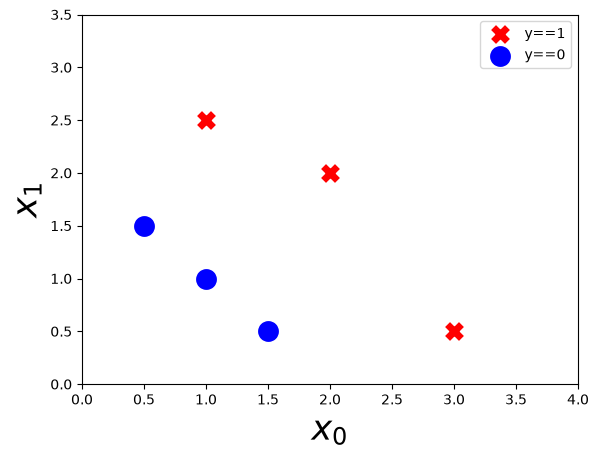

In [3]:
# visualize our data points
positive = y_train == 1
negative = y_train == 0

plt.scatter(X_train[positive, 0], X_train[positive, 1], c='r', marker='x', s=100, lw=5, label='y==1')
plt.scatter(X_train[negative, 0], X_train[negative, 1], c='b', marker='o', s=100, lw=5, label='y==0')
plt.xlabel('$x_0$', size='25')
plt.ylabel('$x_1$', size='25')
plt.axis([0,4,0,3.5])
plt.legend()
plt.show()

In [4]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

In [5]:
def compute_cost_logistic(X, y, w, b):
    m = X.shape[0] # no of training examples
    cost = 0
    for i in range(m):
        z = np.dot(X[i], w) + b
        f_wb_i = sigmoid(z)
        cost += -y[i] * np.log(f_wb_i) - (1-y[i]) * np.log(1 - f_wb_i)
    cost = cost / m
    return cost

In [6]:
def compute_gradient_logistic(X, y, w, b):
    m, n = X.shape # no. of training examples and features
    dj_dw = np.zeros(n)
    dj_db = 0
    for i in range(m):
        z = np.dot(X[i], w) + b
        f_wb_i = sigmoid(z)
        err = f_wb_i - y[i]
        for j in range(n):
            dj_dw[j] += err * X[i][j]
        dj_db += err
    dj_db /= m
    dj_dw /= m
    return dj_dw, dj_db

In [7]:
def gradient_descent(X, y, w_in, b_in, alpha, num_iters):

    w = copy.deepcopy(w_in)
    b = b_in

    hist = dict()
    hist['iteration'] = []
    hist['cost'] = []
    hist['parameters'] = []
    hist['gradients'] = []
    
    for i in range(num_iters):
        dj_dw, dj_db = compute_gradient_logistic(X, y, w, b)

        w = w - alpha * dj_dw
        b = b - alpha * dj_db

        hist['iteration'].append(i)
        hist['cost'].append(compute_cost_logistic(X, y, w, b))
        hist['parameters'].append((w, b))
        hist['gradients'].append((dj_dw, dj_db))

        if i % math.ceil(num_iters / 10) == 0:
            print(f"Iteration {i:4}, Cost: {hist['cost'][-1]}")

    return w, b, hist

In [8]:
# let's run gradient func
X_tmp = np.array([[0.5, 1.5], [1,1], [1.5, 0.5], [3, 0.5], [2, 2], [1, 2.5]])
y_tmp = np.array([0, 0, 0, 1, 1, 1])
w_tmp = np.array([2.,3.])
b_tmp = 1.
dj_dw_tmp, dj_db_tmp = compute_gradient_logistic(X_tmp, y_tmp, w_tmp, b_tmp)
print(f"dj_db: {dj_db_tmp}" )
print(f"dj_dw: {dj_dw_tmp.tolist()}" )

dj_db: 0.49861806546328574
dj_dw: [0.498333393278696, 0.49883942983996693]


In [9]:
# now let's run the gradient descent function and see
w_tmp  = np.zeros_like(X_train[0])
b_tmp  = 0.
alph = 0.1
iters = 10000

w_out, b_out, _ = gradient_descent(X_train, y_train, w_tmp, b_tmp, alph, iters) 
print(f"\nupdated parameters: w:{w_out}, b:{b_out}")

Iteration    0, Cost: 0.684610468560574
Iteration 1000, Cost: 0.1590977666870457
Iteration 2000, Cost: 0.08460064176930078
Iteration 3000, Cost: 0.05705327279402531
Iteration 4000, Cost: 0.04290759421682
Iteration 5000, Cost: 0.03433847729884557
Iteration 6000, Cost: 0.02860379802212006
Iteration 7000, Cost: 0.02450156960879306
Iteration 8000, Cost: 0.02142370332569295
Iteration 9000, Cost: 0.019030137124109114

updated parameters: w:[5.28123029 5.07815608], b:-14.222409982019837


In [10]:
# hurrayyy as we can see above our cost is constantly reducing and we've found the parameters w and b where cost is minimum

In [11]:
# finding decision boundary
# usually we plot our decision boundary where probability = 0.5, and so 
# where the function w0*x0 + w1*x1 + b = 0 (we have understood this quite briefly)
# now to find the decison boundary find x1_intercept and x2_intercept of above function where it 
# intersects the both axis because that's where decision boundary would be
# x0 intercept -> where x0 = 0 -> so 0 + w1*x1 + b = 0 -> x1 = -b/w1
# similarly x1 intercept -> where x1 is 0 -> x0 = -b/w0
# we'll plot these two points and join them to find the decision boundaryy
# these two points (0,x1), (x0, 0) 
# x-coordinates -> [0,x0], y-coordinates -> [x1,0]

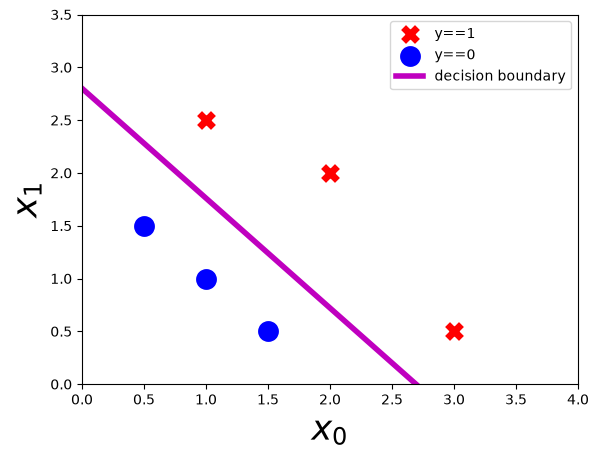

In [12]:
# plot our data
positive = y_train == 1
negative = y_train == 0

plt.scatter(X_train[positive, 0], X_train[positive, 1], c='r', marker='x', s=100, lw=5, label='y==1')
plt.scatter(X_train[negative, 0], X_train[negative, 1], c='b', marker='o', s=100, lw=5, label='y==0')
plt.xlabel('$x_0$', size='25')
plt.ylabel('$x_1$', size='25')
plt.axis([0,4,0,3.5])

# plot decision boundary
x0 = -b_out / w_out[0]
x1 = -b_out / w_out[1]
plt.plot([0,x0], [x1,0], c='m', lw=4, label='decision boundary')

plt.legend()
plt.show()